In [1]:
# Implied volatility by Newton-Raphson method
import math
import numpy as np
from scipy.stats import norm


def get_parameters():
    S0 = float(input("Current stock price (S0): "))
    K = float(input("Strike price (K): "))
    r = float(input("Risk-free rate (e.g. 0.05): "))
    T = float(input("Time to maturity (years): "))
    
    return S0, K, r, T

def black_scholes_call(S0, K, r, sigma, T):

        d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

        d2 = d1 - sigma * np.sqrt(T)

        N = lambda x: 0.5 * (1 + math.erf(x / np.sqrt(2)))

        call_price = S0 * N(d1) - K * np.exp(-r * T) * N(d2)

        return call_price

def pricing_error(call_price, market_price):
    err= call_price - market_price
    return err

def vega(S0, K, T, r, sigma):

    d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))

    return S0 * norm.pdf(d1) * np.sqrt(T)


def implied_volatility(S0,K,r,T, market_price,initial_guess= 0.2,tolerance= 10**(-8), max_iterations=100):
    sigma = initial_guess

    for i in range(max_iterations):
        call_price = black_scholes_call(S0, K, r, sigma, T)
        err = pricing_error(call_price, market_price)
        v = vega(S0, K, T, r, sigma)
        if v < 1e-8:
            print("Vega too small.")
            break
        if abs(err) < tolerance:
            return sigma
            break
        else:
            sigma = sigma- err/v
    return None

S0, K, r, T = get_parameters()

true_sigma = 0.30

market_price = black_scholes_call(S0, K, r, true_sigma, T)

iv = implied_volatility(S0,K,r,T,market_price)

print(f"Recovered Implied Volatility = {iv:.8f}")
print(f"Actual Volatility            = {true_sigma:.8f}")

Recovered Implied Volatility = 0.30000000
Actual Volatility            = 0.30000000


Index(['Unnamed: 0', 'OI', 'CHNG IN OI', 'VOLUME', 'IV', 'LTP', 'CHNG',
       'BID QTY', 'BID', 'ASK', 'ASK QTY', 'STRIKE', 'BID QTY.1', 'BID.1',
       'ASK.1', 'ASK QTY.1', 'CHNG.1', 'LTP.1', 'IV.1', 'VOLUME.1',
       'CHNG IN OI.1', 'OI.1', 'Unnamed: 22'],
      dtype='str')
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.


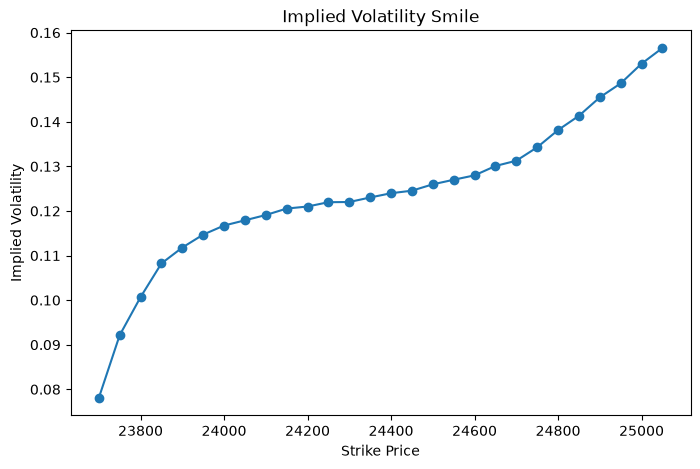

40
28


In [3]:
#IV smile/skew/smirk

import pandas as pd
import matplotlib.pyplot as plt

S0 = 24078.5          # Underlying Index from NSE website
r = 0.06              # Risk-free rate (6%)
T = 5/365           #  expiry is a month away away as of 16th July

spread = int(input("Strike range around spot (e.g. 500): "))

df = pd.read_csv("option_chain21J.csv", skiprows=1)
print(df.columns)

df = df[[ "STRIKE", "LTP","IV"]]

df = df[df["LTP"] != "-"]
df = df.dropna()

df["LTP"] = (df["LTP"].str.replace(",", "").astype(float))
df["STRIKE"] = (df["STRIKE"].str.replace(",", "").astype(float))

df = df[(df["STRIKE"] >= S0 - spread) &
        (df["STRIKE"] <= S0 + spread)]
#df= df[(df["LTP"]) > 5]

strikes = []
ivs = []

for K, market_price in zip(df["STRIKE"], df["LTP"]):

    iv = implied_volatility(
        S0,
        K,
        r,
        T,
        market_price
    )

    if iv is not None:
        strikes.append(K)
        ivs.append(iv)

plt.figure(figsize=(8,5))

plt.plot(strikes, ivs, marker="o")

plt.xlabel("Strike Price")
plt.ylabel("Implied Volatility")
plt.title("Implied Volatility Smile")

plt.show()

print(len(df))
print(len(ivs))



Processing option_chain21J.csv
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Processing option_chain28J.csv
Vega too small.
Vega too small.
Vega too small.
Processing option_chain4A.csv
Vega too small.
Processing option_chain11A.csv
Processing option_chain25A.csv
Vega too small.
Processing option_chain29S.csv
Processing option_chain29D.csv


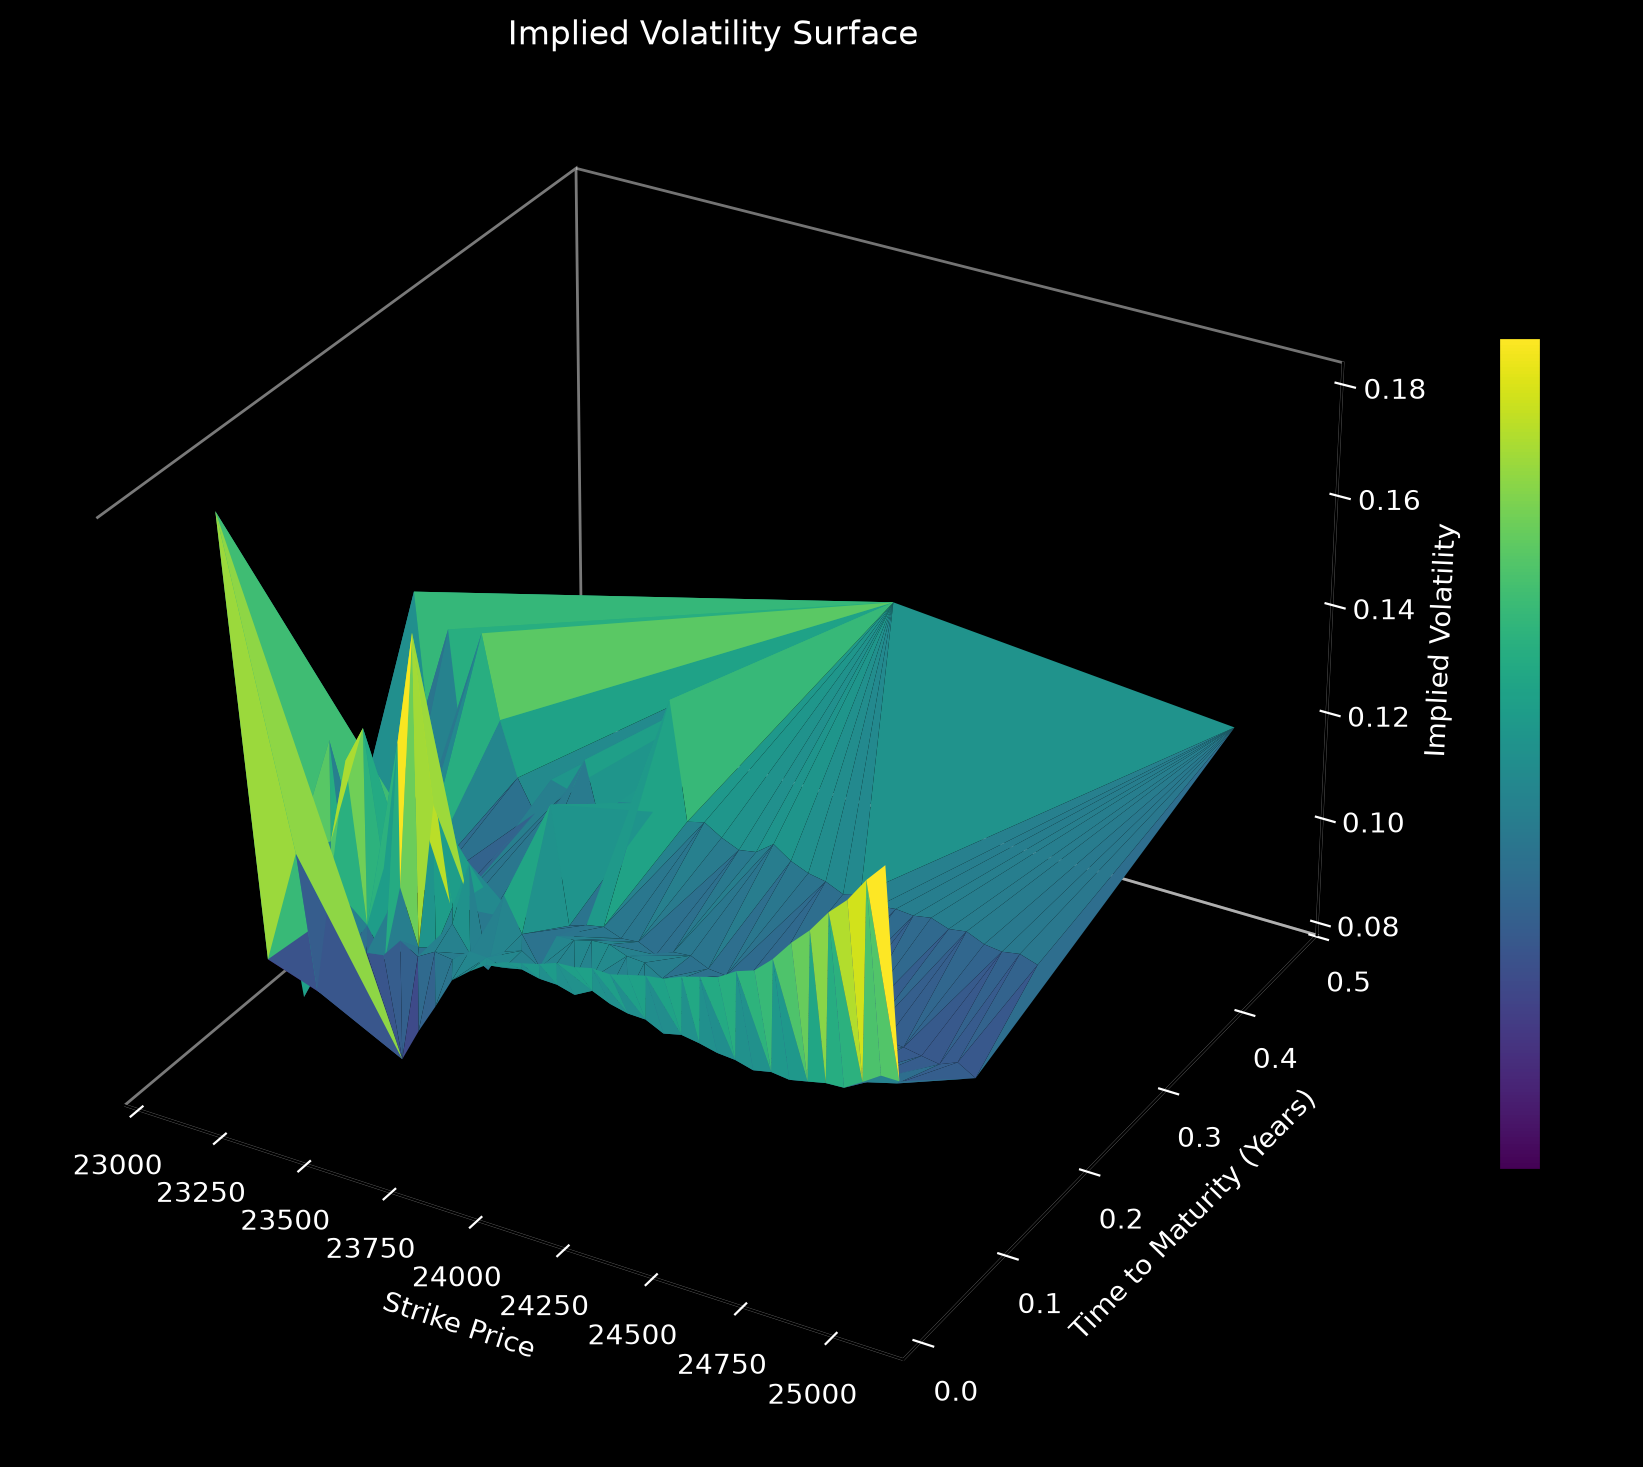

In [2]:
#trinagulation 
import pandas as pd

S0 = 24072.75
r = 0.06

spread = int(input("Strike range around spot: "))

files = [("option_chain21J.csv", 5/365),("option_chain28J.csv", 12/365),("option_chain4A.csv", 19/365),("option_chain11A.csv", 26/365),("option_chain25A.csv", 45/365),
    ("option_chain29S.csv", 80/365),("option_chain29D.csv", 171/365)]

all_data = pd.DataFrame(columns=["Strike", "T", "IV"])

for file, T in files:

    print(f"Processing {file}")

    df = pd.read_csv(file, skiprows=1)

    df = df[["STRIKE", "LTP", "IV"]]

    df = df[df["LTP"] != "-"]
    df = df.dropna()

    df["LTP"] = df["LTP"].str.replace(",", "").astype(float)
    df["STRIKE"] = df["STRIKE"].str.replace(",", "").astype(float)

    df = df[(df["STRIKE"] >= S0 - spread) &
            (df["STRIKE"] <= S0 + spread)]

    strikes = []
    ivs = []

    for K, market_price in zip(df["STRIKE"], df["LTP"]):

        iv = implied_volatility(
            S0,
            K,
            r,
            T,
            market_price
        )

        if iv is not None:
            strikes.append(K)
            ivs.append(iv)

    # Store this expiry's data
    temp = pd.DataFrame({
        "Strike": strikes,
        "T": [T] * len(strikes),
        "IV": ivs
    })

    all_data = pd.concat([all_data, temp], ignore_index=True)

all_data["Strike"] = pd.to_numeric(all_data["Strike"], errors="coerce")
all_data["T"] = pd.to_numeric(all_data["T"], errors="coerce")
all_data["IV"] = pd.to_numeric(all_data["IV"], errors="coerce")

all_data = all_data.dropna()
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12,9),dpi=200, facecolor="black")
ax = fig.add_subplot(111, projection="3d")
ax.set_facecolor("black")
surf = ax.plot_trisurf(
    all_data["Strike"],
    all_data["T"],
    all_data["IV"],
    linewidth=0,antialiased="true",
    cmap="viridis",
    edgecolor="none"
)

fig.colorbar(surf, ax=ax, shrink=0.6)

ax.set_xlabel("Strike Price",color="white")
ax.set_ylabel("Time to Maturity (Years)",color="white")
ax.set_zlabel("Implied Volatility",color="white")
ax.set_title("Implied Volatility Surface",color="white")
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='z', colors='white')
ax.grid(False)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
plt.show()




Processing option_chain21J.csv
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Vega too small.
Processing option_chain28J.csv
Vega too small.
Vega too small.
Vega too small.
Processing option_chain4A.csv
Vega too small.
Processing option_chain11A.csv
Processing option_chain25A.csv
Vega too small.
Processing option_chain29S.csv
Processing option_chain29D.csv


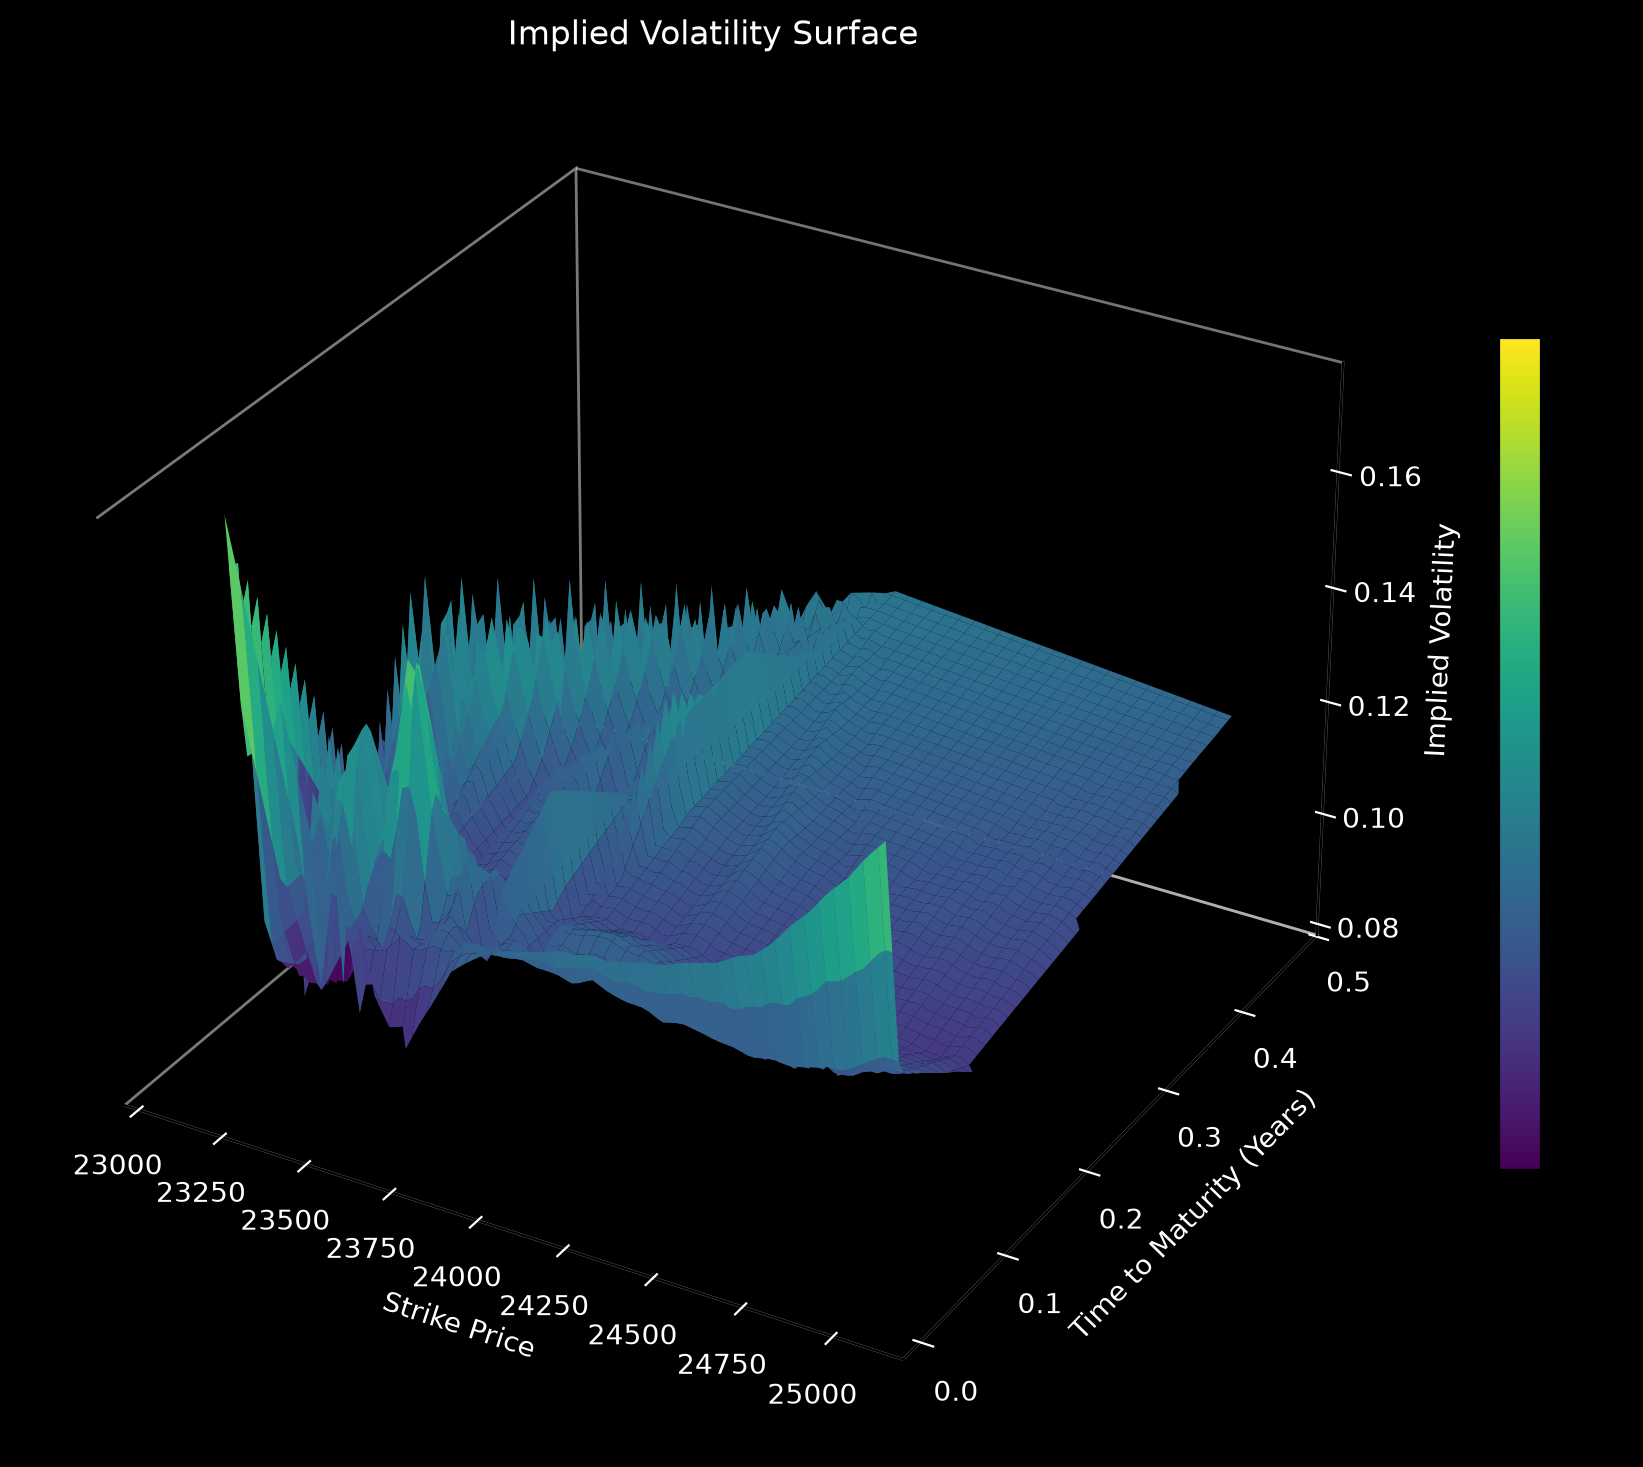

In [24]:
#Interpolation
import pandas as pd

S0 = 24072.75
r = 0.06

spread = int(input("Strike range around spot: "))

files = [("option_chain21J.csv", 5/365),("option_chain28J.csv", 12/365),("option_chain4A.csv", 19/365),("option_chain11A.csv", 26/365),("option_chain25A.csv", 45/365),
    ("option_chain29S.csv", 80/365),("option_chain29D.csv", 171/365)]

all_data = pd.DataFrame(columns=["Strike", "T", "IV"])

for file, T in files:

    print(f"Processing {file}")

    df = pd.read_csv(file, skiprows=1)

    df = df[["STRIKE", "LTP", "IV"]]

    df = df[df["LTP"] != "-"]
    df = df.dropna()

    df["LTP"] = df["LTP"].str.replace(",", "").astype(float)
    df["STRIKE"] = df["STRIKE"].str.replace(",", "").astype(float)

    df = df[(df["STRIKE"] >= S0 - spread) &
            (df["STRIKE"] <= S0 + spread)]

    strikes = []
    ivs = []

    for K, market_price in zip(df["STRIKE"], df["LTP"]):

        iv = implied_volatility(
            S0,
            K,
            r,
            T,
            market_price
        )

        if iv is not None:
            strikes.append(K)
            ivs.append(iv)

    # Store this expiry's data
    temp = pd.DataFrame({
        "Strike": strikes,
        "T": [T] * len(strikes),
        "IV": ivs
    })

    all_data = pd.concat([all_data, temp], ignore_index=True)

all_data["Strike"] = pd.to_numeric(all_data["Strike"], errors="coerce")
all_data["T"] = pd.to_numeric(all_data["T"], errors="coerce")
all_data["IV"] = pd.to_numeric(all_data["IV"], errors="coerce")

all_data = all_data.dropna()

from scipy.interpolate import griddata
strike_grid = np.linspace(
    all_data["Strike"].min(),
    all_data["Strike"].max(),
    100)

T_grid = np.linspace(
    all_data["T"].min(),
    all_data["T"].max(),
    100)

X, Y = np.meshgrid(strike_grid, T_grid)
Z = griddata(
    (all_data["Strike"], all_data["T"]),
    all_data["IV"],
    (X, Y),
    method="linear")

from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(12,9),dpi=200, facecolor="black")
ax = fig.add_subplot(111, projection="3d")
ax.set_facecolor("black")
surf = ax.plot_surface(X,Y,Z,
    linewidth=0,antialiased=True,
    cmap="viridis",
    edgecolor="none")

fig.colorbar(surf, ax=ax, shrink=0.6)

ax.set_xlabel("Strike Price",color="white")
ax.set_ylabel("Time to Maturity (Years)",color="white")
ax.set_zlabel("Implied Volatility",color="white")
ax.set_title("Implied Volatility Surface",color="white")
ax.tick_params(axis='x', colors='white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='z', colors='white')
ax.grid(False)
ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
plt.show()


